> **Solutions version.** Try the student version first; use this one to check your work and as a reference for the guided project.

# Lab: Measuring Size and Sensitivity
**MATH 3515 Numerical Analysis · Error and Sensitivity, Parts 1–2 · Week 11, completed outside class**

This lab is designed for **two sittings**, about **85 minutes of core work** in all. Stop at the **Checkpoint** after Topic 5 and continue with Part B another day. Topics marked *If time* are optional; partial completion of them is fine.

### Learning outcomes
**Part A, Measuring Size.** By the end of Part A, you will be able to:
- A1. **Compute** vector norms with NumPy and **verify** the inequalities ‖x‖∞ ≤ ‖x‖₂ ≤ ‖x‖₁ and ‖x‖₂ ≤ √n‖x‖∞ on many vectors.
- A2. **Implement** the p-norm and **explain**, using its values, why the max-norm is called the ∞-norm.
- A3. **Explain** why a matrix norm estimated from random vectors falls short of the true value, using where the maximum stretch occurs.
- A4. **Compare** ‖Mᵏ‖ with ‖M‖ᵏ and **describe** how loose the submultiplicative bound can become.
- A5. **Interpret** the error, the step size, and the stopping test of a vector iteration, and **recognize** that a small step does not guarantee a small error.
- A6. **Approximate** norms of a function on a grid and **relate** the results to the exact values.

**Part B, Measuring Sensitivity.** By the end of Part B, you will be able to:
- B1. **Compute** the condition number of a matrix and **check** the error bound ‖Δx‖/‖x‖ ≤ κ(A)‖Δb‖/‖b‖ on many perturbations.
- B2. **Use** κ to **predict** how many digits a computed solution loses, and **explain** why a computed condition number can itself be unreliable.
- B3. **Relate** the singular values of a 2×2 matrix to the image of the unit circle.
- B4. **Implement** the Cholesky factorization and **use** it both to solve a system and to test for positive definiteness.
- B5. **Distinguish** a sensitive problem (conditioning) from an unstable algorithm (stability) using κ and the residual.

### How to work
- Run the cells **from top to bottom** (in Colab: Runtime → Run all, or Shift+Enter cell by cell).
- **Predict before you run** wherever a cell asks for a prediction. A wrong prediction is useful: it shows you what to look at.
- Replace every `___` with your code. There are five, in Topics 2 and 6, each with a comment `# blank N: what to write`.
- **Check your work** cells tell you right away if something is off.
- Topics 6, 11 and 12 are *If time*. Finishing the core topics counts as success.

| Part | Topic | Builds on | Mode | AI use | Minutes |
|---|---|---|---|---|---|
| | Setup | | | | 2 |
| A | 1. Norms of a vector, and the inequalities on many vectors | PS1 Ex 1–2 | Run and interpret | Level 0 | 7 |
| A | 2. The p-norm, and why ∞ | PS1 Ex 3 | Write code | Level 0 | 10 |
| A | 3. Estimating ‖M‖∞ from random vectors | PS1 Ex 4 | Run and interpret | Level 0 | 8 |
| A | 4. How loose is ‖Mᵏ‖ ≤ ‖M‖ᵏ? | PS1 Ex 5 | Run and interpret, optional AI-assisted task | Level 2 (optional part) | 8 |
| A | 5. A vector iteration and its stopping test | PS1 Ex 6 | Run and interpret | Level 0 | 12 |
| A | 6. *If time:* Norms of a function on a grid | PS1 Ex 7 | Write code | Level 0 | 10 |
| B | 7. κ against ε, and the error bound on many perturbations | PS2 Ex 1–2 | Run and interpret, optional AI-assisted task | Level 2 (optional part) | 12 |
| B | 8. κ explains the Week 7 error table | PS2 Ex 3 | Run and interpret | Level 0 | 10 |
| B | 9. The unit circle becomes an ellipse | PS2 Ex 4 | Run and interpret | Level 0 | 8 |
| B | 10. Cholesky from the hand steps | PS2 Ex 5 | Run and interpret | Level 0 | 8 |
| B | 11. *If time:* A norm bigger than 1 that still converges | PS2 Ex 6 | Run and interpret | Level 0 | 8 |
| B | 12. *If time:* Conditioning vs. stability, with κ printed | PS2 Ex 7 | Run and interpret | Level 0 | 8 |

**AI use in this lab.** Most topics are **Level 0 (AI Free)**: you run, read, predict and explain on your own, and in Topics 2 and 6 you fill short blanks yourself. Topics 4 and 7 contain an **optional Level 2 (AI Collaboration)** task. There you may ask an assistant to write the code, but you must then **verify it against the problem-set hand answer** and fill in the disclosure cell (tool, prompt, what you changed). These two topics are the only places where an assistant may write code. If you skip the optional task, a given cell supplies working code and everything below still runs.

### Setup
Run this cell first. It loads NumPy and matplotlib and defines the objects from Problem Sets 1 and 2. All matrices are stored as floats.

In [1]:
%matplotlib inline
import inspect
import math
import time

import numpy as np
import matplotlib.pyplot as plt

np.set_printoptions(precision=4, suppress=True)
rng = np.random.default_rng(3515)

# Blanks in this notebook are written ___ . IPython normally stores old outputs in
# a variable called ___, so an unfilled blank would not raise an error. Turn that off.
# (Side effect: _, __, ___ no longer hold previous outputs.)
try:
    get_ipython().displayhook.cache_size = 0
    del ___
except NameError:
    pass

# Problem Set 1 (Part A)
v = np.array([2.0, -3.0, 6.0])
u = np.array([0.6, 0.8])
M = np.array([[1.0, 2.0], [-3.0, 4.0]])
G = np.array([[0.5, 0.25], [0.25, 0.5]])
c = np.array([1.0, 1.0])
x_bar = np.array([4.0, 4.0])          # fixed point of x = G x + c


def f(x):
    return x * (1 - x)


# Problem Set 2 (Part B)
def A_eps(eps):
    return np.array([[1.0, 1.0], [1.0, 1.0 + eps]])


K = np.array([[4.0, -2.0, 0.0], [-2.0, 5.0, -2.0], [0.0, -2.0, 5.0]])
G2 = np.array([[0.5, 1.0], [0.0, 0.5]])


def hilbert(n):
    i = np.arange(1, n + 1)
    return 1.0 / (i[:, None] + i[None, :] - 1)


eps_mach = np.finfo(float).eps


def show(name, value):
    print(f"{name:<32s} {value}")


# Okabe-Ito colorblind-safe colors; plots also use different markers and line styles
OI = ["#0072B2", "#D55E00", "#009E73", "#CC79A7", "#E69F00", "#56B4E9", "#000000"]
print("Setup done. NumPy", np.__version__)

Setup done. NumPy 2.0.2


---
# Part A. Measuring Size
Topics 1–6 build on **Problem Set 1**.

## Topic 1. Norms of a vector, and the inequalities on many vectors
*Mode: Run and interpret · AI use: Level 0 (AI Free) · About 7 min · builds on PS1 Ex 1 and 2*

**Goal:** compute three norms with NumPy and test the norm inequalities on thousands of vectors.

**Connect.** In PS1 Ex 1 you found $\|\mathbf{v}\|_1 = 11$, $\|\mathbf{v}\|_2 = 7$, $\|\mathbf{v}\|_\infty = 6$. In Ex 2 you proved $\|\mathbf{x}\|_\infty \le \|\mathbf{x}\|_2 \le \|\mathbf{x}\|_1$ and $\|\mathbf{x}\|_2 \le \sqrt{n}\,\|\mathbf{x}\|_\infty$.

**Run 1.** `np.linalg.norm(x, p)` computes $\|\mathbf{x}\|_p$. For vectors, `ord=2` is the default, so `np.linalg.norm(v)` is the 2-norm.

In [2]:
show("||v||_1", np.linalg.norm(v, 1))
show("||v||_2", np.linalg.norm(v))          # ord=2 is the default for vectors
show("||v||_inf", np.linalg.norm(v, np.inf))

||v||_1                          11.0
||v||_2                          7.0
||v||_inf                        6.0


**Predict.** We will test the inequalities on 10,000 random vectors in $\mathbb{R}^5$. How many failures do you expect? What is the largest ratio $\|\mathbf{x}\|_2/\|\mathbf{x}\|_\infty$ you expect to see, compared with $\sqrt{5} \approx 2.236$?

*Sample answer.* No failures: the inequalities are theorems, so they hold for every vector. The largest ratio should be below √5, perhaps around 2, because reaching √5 needs all five entries equal in size.

**Run 2.** The four inequalities are $\|\mathbf{x}\|_\infty \le \|\mathbf{x}\|_2$, $\|\mathbf{x}\|_2 \le \|\mathbf{x}\|_1$, $\|\mathbf{x}\|_2 \le \sqrt{n}\,\|\mathbf{x}\|_\infty$ and $\|\mathbf{x}\|_1 \le \sqrt{n}\,\|\mathbf{x}\|_2$ (PS1 Ex 2(f)). The function below draws 10,000 standard-normal vectors (with its own generator, seed 3515, so the results are reproducible), counts the failures with a relative tolerance of $10^{-12}$, and returns the ratios.

In [3]:
def ratio_experiment(n, N=10_000, seed=3515):
    # Test the four norm inequalities on N standard-normal vectors in R^n.
    rng_local = np.random.default_rng(seed)
    X = rng_local.standard_normal((N, n))
    n1 = np.linalg.norm(X, 1, axis=1)
    n2 = np.linalg.norm(X, 2, axis=1)
    ninf = np.linalg.norm(X, np.inf, axis=1)
    tol = 1e-12
    failures = {
        "||x||_inf <= ||x||_2": int(np.sum(ninf > n2 * (1 + tol))),
        "||x||_2 <= ||x||_1": int(np.sum(n2 > n1 * (1 + tol))),
        "||x||_2 <= sqrt(n) ||x||_inf": int(np.sum(n2 > np.sqrt(n) * ninf * (1 + tol))),
        "||x||_1 <= sqrt(n) ||x||_2": int(np.sum(n1 > np.sqrt(n) * n2 * (1 + tol))),
    }
    return failures, n2 / ninf, n1 / n2


n = 5
failures, ratio_2_inf, ratio_1_2 = ratio_experiment(n)
for name, count in failures.items():
    print(f"failures of {name:<30s} {count}")
print(f"largest ||x||_2/||x||_inf = {ratio_2_inf.max():.4f}    sqrt(n) = {np.sqrt(n):.4f}")
print(f"largest ||x||_1/||x||_2   = {ratio_1_2.max():.4f}    sqrt(n) = {np.sqrt(n):.4f}")

failures of ||x||_inf <= ||x||_2           0
failures of ||x||_2 <= ||x||_1             0
failures of ||x||_2 <= sqrt(n) ||x||_inf   0
failures of ||x||_1 <= sqrt(n) ||x||_2     0
largest ||x||_2/||x||_inf = 2.0893    sqrt(n) = 2.2361
largest ||x||_1/||x||_2   = 2.2338    sqrt(n) = 2.2361


**Plot.** The histogram shows how the 10,000 values of $\|\mathbf{x}\|_2/\|\mathbf{x}\|_\infty$ are spread for $n = 5$. Dashed vertical lines mark the lower bound 1 and the upper bound $\sqrt{5}$; most values sit in the middle and none reaches either line.

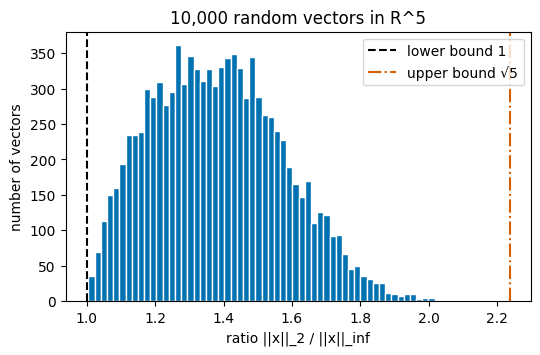

In [4]:
fig, ax = plt.subplots(figsize=(6, 3.5))
ax.hist(ratio_2_inf, bins=60, color=OI[0], edgecolor="white")
ax.axvline(1, color=OI[6], linestyle="--", label="lower bound 1")
ax.axvline(np.sqrt(n), color=OI[1], linestyle="-.", label=f"upper bound √{n}")
ax.set_xlabel("ratio ||x||_2 / ||x||_inf")
ax.set_ylabel("number of vectors")
ax.set_title(f"10,000 random vectors in R^{n}")
ax.legend()
plt.show()

**Interpret.**

(a) True or false, with a reason: "If no random vector reaches $\sqrt{n}$, the bound $\sqrt{n}$ must be too large."

*Sample answer.* False. The bound is reached by $(1, 1, \dots, 1)$ (PS1 Ex 2(e)), so it cannot be lowered. Random vectors almost never have all $|x_i|$ equal, so not reaching the bound says nothing about whether it is too large.

(b) Multiple choice: which vector would reach $\|\mathbf{x}\|_2/\|\mathbf{x}\|_\infty = \sqrt{n}$? (all entries equal in size / one nonzero entry / random)

*Sample answer.* All entries equal in size. One nonzero entry gives the lower bound 1.

**Explore.** Change `n_explore` to 2, 10 and 100 and rerun. How does the largest observed ratio compare with $\sqrt{n}$ as $n$ grows?

In [5]:
n_explore = 10     # change to 2, 10, 100
_, r2, r1 = ratio_experiment(n_explore)
print(f"n = {n_explore}: largest ||x||_2/||x||_inf = {r2.max():.4f}, "
      f"largest ||x||_1/||x||_2 = {r1.max():.4f}, sqrt(n) = {np.sqrt(n_explore):.4f}")

n = 10: largest ||x||_2/||x||_inf = 2.5574, largest ||x||_1/||x||_2 = 3.0908, sqrt(n) = 3.1623


*Sample answer.* For $n = 2$ the largest ratio is 1.4141, almost $\sqrt{2} = 1.4142$; for $n = 10$ it is 2.557 against 3.162; for $n = 100$ it is 5.10 against 10. As $n$ grows, the largest observed ratio falls farther below $\sqrt{n}$, because having all $n$ entries nearly equal in size becomes very unlikely.

**Takeaway.** The inequalities hold for every vector, and the constant $\sqrt{n}$ is reached only by special vectors (all $|x_i|$ equal):
$$\|\mathbf{x}\|_\infty \le \|\mathbf{x}\|_2 \le \|\mathbf{x}\|_1, \qquad \|\mathbf{x}\|_2 \le \sqrt{n}\,\|\mathbf{x}\|_\infty, \qquad \|\mathbf{x}\|_1 \le \sqrt{n}\,\|\mathbf{x}\|_2.$$
Random vectors can come close to √n in low dimensions (n = 2, 5), but reach it only when all |xᵢ| are equal; as n grows, random vectors stay farther from the bound.

**Confidence check, Topic 1.** Mark one: Got it ☐ · Getting there ☐ · Need more practice ☐

## Topic 2. The p-norm, and why ∞
*Mode: Write code · AI use: Level 0 (AI Free) · About 10 min · builds on PS1 Ex 3*

**Goal:** write the p-norm yourself and see why the max-norm is the limit p → ∞.

**Connect.** In PS1 Ex 3: $\|\mathbf{u}\|_1 = 1.4$, $\|\mathbf{u}\|_2 = 1$, $\|\mathbf{u}\|_4 \approx 0.857$, $\|\mathbf{u}\|_\infty = 0.8$.

**Run (you write).** Fill in the two blanks. For finite $p$, $\|\mathbf{x}\|_p = \left(|x_1|^p + \cdots + |x_n|^p\right)^{1/p}$; for $p = \infty$ it is the largest $|x_i|$. Useful NumPy: `np.abs`, `np.sum`, `np.max`, and `**` for powers.

In [6]:
def pnorm(x, p):
    # p-norm of the vector x, for p >= 1 or p = np.inf
    x = np.asarray(x, dtype=float)
    if p != np.inf:
        return np.sum(np.abs(x)**p)**(1/p)  # blank 1: (|x_1|^p + ... + |x_n|^p)^(1/p)
    return np.max(np.abs(x))  # blank 2: the largest entry in absolute value

**Check your work.** Run this cell. It compares your `pnorm` with the Problem Set 1 values and with `np.linalg.norm`.

In [7]:
for p, expected in [(1, 1.4), (2, 1.0), (4, 0.857), (np.inf, 0.8)]:
    value = pnorm(u, p)
    assert abs(value - expected) < 1e-3, (
        f"pnorm(u, {p}) = {value:.4f}, but Problem Set 1, Ex 3 gives {expected}. Check blanks 1 and 2.")
for x in (v, u):
    for p in (1, 2, 3, np.inf):
        assert np.isclose(pnorm(x, p), np.linalg.norm(x, p)), (
            f"pnorm({x}, {p}) = {pnorm(x, p):.4f}, but np.linalg.norm gives {np.linalg.norm(x, p):.4f}. "
            "Did you use absolute values?")
assert pnorm(-v, np.inf) == 6, "pnorm(-v, np.inf) should be 6: use absolute values in the infinity case."
print("Topic 2 check passed.")

Topic 2 check passed.


**Plot 1.** The curve shows $\|\mathbf{u}\|_p$ for $p$ from 1 to 30, falling from 1.4 toward the dashed horizontal line at $\|\mathbf{u}\|_\infty = 0.8$, which it approaches but never crosses.

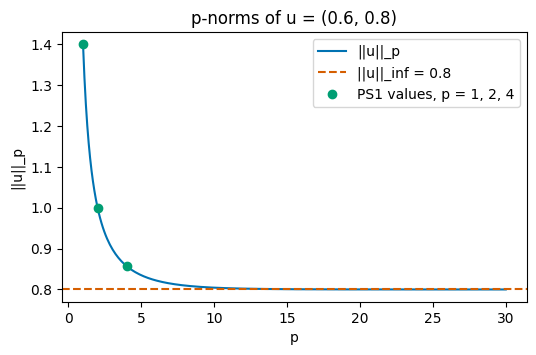

||u||_30 - 0.8 = 4.76e-06


In [8]:
ps = np.linspace(1, 30, 300)
values = [pnorm(u, p) for p in ps]
fig, ax = plt.subplots(figsize=(6, 3.5))
ax.plot(ps, values, color=OI[0], linestyle="-", label="||u||_p")
ax.axhline(0.8, color=OI[1], linestyle="--", label="||u||_inf = 0.8")
ax.plot([1, 2, 4], [pnorm(u, 1), pnorm(u, 2), pnorm(u, 4)], "o", color=OI[2], label="PS1 values, p = 1, 2, 4")
ax.set_xlabel("p")
ax.set_ylabel("||u||_p")
ax.set_title("p-norms of u = (0.6, 0.8)")
ax.legend()
plt.show()
print(f"||u||_30 - 0.8 = {pnorm(u, 30) - 0.8:.2e}")

**Predict.** Sketch what you think the unit ball (the curve $\|\mathbf{x}\|_p = 1$) looks like for $p = 10$.

*Sample answer.* Close to the square $\|\mathbf{x}\|_\infty = 1$, with rounded corners.

**Plot 2.** Unit-ball boundaries $\|\mathbf{x}\|_p = 1$ for $p = 1, 2, 4, 10, \infty$ on one set of axes, each with its own line style. Each curve takes the points $(\cos\theta, \sin\theta)$ and divides them by their p-norm. The diamond ($p = 1$) is innermost; as $p$ grows the curves bulge outward toward the square ($p = \infty$).

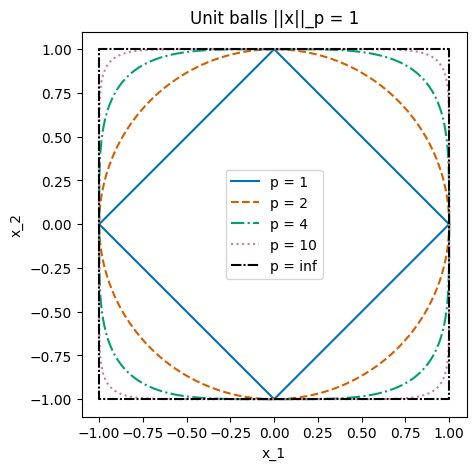

In [9]:
theta = np.linspace(0, 2 * np.pi, 721)
styles = [(1, "-", OI[0]), (2, "--", OI[1]), (4, "-.", OI[2]), (10, ":", OI[3]), (np.inf, (0, (5, 1, 1, 1)), OI[6])]
fig, ax = plt.subplots(figsize=(5, 5))
for p, ls, col in styles:
    pts = np.array([[np.cos(t), np.sin(t)] for t in theta])
    pts = pts / np.array([pnorm(q, p) for q in pts])[:, None]
    ax.plot(pts[:, 0], pts[:, 1], linestyle=ls, color=col, label=f"p = {p}")
ax.set_aspect("equal")
ax.set_xlabel("x_1")
ax.set_ylabel("x_2")
ax.set_title("Unit balls ||x||_p = 1")
ax.legend(loc="center")
plt.show()

**Interpret.**

(a) Read off Plot 1 (and the printed line): at $p = 30$, how far is $\|\mathbf{u}\|_p$ from 0.8?

*Sample answer.* About $5 \times 10^{-6}$ (printed: 4.76e-06). On the plot the curve sits on the dashed line.

(b) One sentence: why do the curves in Plot 2 approach the square?

*Sample answer.* Raising the entries to a high power makes the largest $|x_i|$ dominate the sum, so $\|\mathbf{x}\|_p$ approaches $\max_i |x_i|$, whose unit ball is the square.

**Takeaway.** $\|\mathbf{x}\|_p$ decreases toward $\|\mathbf{x}\|_\infty$ as $p \to \infty$, because the largest entry dominates: $\|\mathbf{u}\|_p = 0.8\,\big((0.6/0.8)^p + 1\big)^{1/p} \to 0.8$. This is why the max-norm is called the ∞-norm.

**Toolkit.** `pnorm` is collected in the project toolkit at the end and reused in later labs and projects.

**Confidence check, Topic 2.** Mark one: Got it ☐ · Getting there ☐ · Need more practice ☐

## Topic 3. Estimating ‖M‖∞ from random vectors
*Mode: Run and interpret · AI use: Level 0 (AI Free) · About 8 min · builds on PS1 Ex 4*

**Goal:** see why sampling vectors gives a lower bound for a matrix norm, and where the maximum stretch occurs.

**Connect.** In PS1 Ex 4: $\|M\|_\infty = 7$, reached at the corners $\pm(1, -1)$ of the square $\|\mathbf{x}\|_\infty = 1$.

PS1 Ex 4(d)–(e): $\|M\mathbf{x}\|_\infty \le \|M\|_\infty\|\mathbf{x}\|_\infty$ for every $\mathbf{x}$; scaling a maximizing corner by 2 doubles both sides. That is why sampling only vectors with $\|\mathbf{x}\|_\infty = 1$ is enough.

**Predict.** If we test 1,000 random vectors with $\|\mathbf{x}\|_\infty = 1$, will the largest $\|M\mathbf{x}\|_\infty$ be exactly 7, a bit below 7, or above 7?

*Sample answer.* A bit below 7. It cannot be above 7, and a random sample will almost never land exactly on a corner.

**Run.** Sample $N$ points uniformly in $[-1, 1]^2$, scale each to $\|\mathbf{x}\|_\infty = 1$ (divide by its largest entry in absolute value), and take the largest $\|M\mathbf{x}\|_\infty$.

In [10]:
def estimate_norm_inf(A, N, seed=3515):
    # Largest ||A x||_inf over N random x with ||x||_inf = 1
    rng_local = np.random.default_rng(seed)
    X = rng_local.uniform(-1, 1, size=(N, A.shape[1]))
    X = X / np.abs(X).max(axis=1, keepdims=True)      # now every row has ||x||_inf = 1
    stretch = np.abs(X @ A.T).max(axis=1)             # ||A x||_inf for each sample
    return stretch.max(), X, stretch


estimate, X3, stretch3 = estimate_norm_inf(M, 1000)
show("estimate from 1000 samples", estimate)
show("np.linalg.norm(M, np.inf)", np.linalg.norm(M, np.inf))

estimate from 1000 samples       6.99949414303962
np.linalg.norm(M, np.inf)        7.0


**Plot.** The sampled points lie on the boundary of the square $\|\mathbf{x}\|_\infty = 1$. Each point is colored *and* sized by its stretch $\|M\mathbf{x}\|_\infty$ (larger and darker means more stretch). The two maximizing corners $\pm(1, -1)$ are marked with black stars and labeled; the largest stretches crowd next to them.

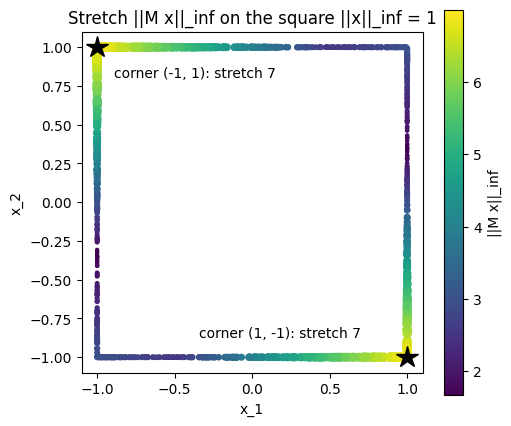

In [11]:
fig, ax = plt.subplots(figsize=(5.5, 5))
sc = ax.scatter(X3[:, 0], X3[:, 1], c=stretch3, s=4 + 6 * (stretch3 - stretch3.min()), cmap="viridis")
fig.colorbar(sc, ax=ax, label="||M x||_inf")
for corner in ([1, -1], [-1, 1]):
    ax.plot(*corner, marker="*", markersize=16, color="black", linestyle="none")
    ax.annotate(f"corner {tuple(corner)}: stretch 7", corner, textcoords="offset points",
                xytext=(12, -22) if corner[1] > 0 else (-150, 14))
ax.set_aspect("equal")
ax.set_xlabel("x_1")
ax.set_ylabel("x_2")
ax.set_title("Stretch ||M x||_inf on the square ||x||_inf = 1")
plt.show()

**Interpret.**

(a) Why is the estimate never above 7?

*Sample answer.* Every sample has $\|\mathbf{x}\|_\infty = 1$, so $\|M\mathbf{x}\|_\infty \le \|M\|_\infty \|\mathbf{x}\|_\infty = 7$ (property (2)). The largest of numbers that are all $\le 7$ is $\le 7$.

(b) Why is it almost never exactly 7? Use PS1 Ex 4(c).

*Sample answer.* The maximum is reached only at the corners $\pm(1, -1)$, where the signs of $\mathbf{x}$ match row 2 of $M$ (PS1 Ex 4(c)). A random sample lands exactly on a corner with probability 0, and a nearby point gives a little less than 7.

**Explore.** The table repeats the estimate for $N = 10, 100, 1000, 10{,}000$ (same seed). Describe how the gap changes.

In [12]:
print(f"{'N':>6s} {'estimate':>10s} {'7 - estimate':>14s}")
for N in (10, 100, 1000, 10_000):
    est, _, _ = estimate_norm_inf(M, N)
    print(f"{N:>6d} {est:>10.5f} {7 - est:>14.2e}")

     N   estimate   7 - estimate
    10    6.46581       5.34e-01
   100    6.97683       2.32e-02
  1000    6.99949       5.06e-04
 10000    6.99983       1.70e-04


*Sample answer.* The gap shrinks as $N$ grows (from about 0.53 at $N = 10$ to about $2 \times 10^{-4}$ at $N = 10{,}000$), but it never reaches 0: more samples come closer to a corner, never exactly onto it.

**Takeaway.** Sampling gives a lower bound for $\|A\|$, never more: $\max_{\text{samples}} \|A\mathbf{x}\| \le \|A\|$. The row-sum formula gives the exact value because it knows where the maximum is.

**Confidence check, Topic 3.** Mark one: Got it ☐ · Getting there ☐ · Need more practice ☐

## Topic 4. How loose is ‖Mᵏ‖ ≤ ‖M‖ᵏ?
*Mode: Run and interpret, with an optional AI-assisted task · AI use: Level 2 (AI Collaboration) for the optional part; Level 0 otherwise · About 8 min · builds on PS1 Ex 5*

**Goal:** compare the true norms of matrix powers with the submultiplicative bound.

**Connect.** In PS1 Ex 5: $\|M^2\|_\infty = 25 \le \|M\|_\infty^2 = 49$.

**Optional task (AI-assisted, Level 2).** Ask your assistant for code that computes $\|M^k\|_\infty$ and $\|M\|_\infty^k$ for $k = 1, \dots, 10$, prints a table, and plots both on a log scale. Paste the code into the next cell and run it. A suggested prompt:

> Write Python code with NumPy. Let `M = np.array([[1.0, 2.0], [-3.0, 4.0]])`. For k = 1, …, 10, compute the infinity norm of the matrix power M^k (the matrix product M·M·…·M, not entrywise powers) and the number ‖M‖∞^k. Store them in two lists named `norm_Mk` and `bound`, where index 0 is k = 1. Print a table with columns k, ‖M^k‖∞, ‖M‖∞^k, and plot both lists against k with a logarithmic y-axis.

If you skip this task, leave the next cell empty: the given cell after it supplies the same lists.

In [13]:
# Optional: AI-assisted (key version of what the assistant should produce)
ks = range(1, 11)
norm_Mk = [np.linalg.norm(np.linalg.matrix_power(M, k), np.inf) for k in ks]
bound = [np.linalg.norm(M, np.inf)**k for k in ks]
print(f"{'k':>3s} {'||M^k||_inf':>14s} {'||M||_inf^k':>14s}")
for k, a, b in zip(ks, norm_Mk, bound):
    print(f"{k:>3d} {a:>14,.0f} {b:>14,.0f}")

  k    ||M^k||_inf    ||M||_inf^k
  1              7              7
  2             25             49
  3             65            343
  4            175          2,401
  5            425         16,807
  6          2,375        117,649
  7          7,625        823,543
  8         20,625      5,764,801
  9         49,375     40,353,607
 10        165,625    282,475,249


**Disclosure (only if you used the optional cell).** Tool used: … · Prompt: … · What I changed in the generated code, and why: …

*Sample answer.* Key version written by hand; no tool used. (A student who used an assistant fills in the tool, the prompt, and every change made, for example replacing `M**k` by `np.linalg.matrix_power(M, k)`.)

**Given.** This cell defines `norm_Mk` and `bound` **only if** the optional cell did not, so your own code is what gets verified when you wrote it.

In [14]:
if "norm_Mk" not in globals() or "bound" not in globals():
    ks = range(1, 11)
    norm_Mk = [np.linalg.norm(np.linalg.matrix_power(M, k), np.inf) for k in ks]
    bound = [np.linalg.norm(M, np.inf)**k for k in ks]
    print("Using the given code for norm_Mk and bound.")
else:
    print("Using norm_Mk and bound from the optional cell.")

Using norm_Mk and bound from the optional cell.


**Verify (required).** Compare with the hand answers of Problem Set 1, Ex 5.

In [15]:
msg = "Your code disagrees with Problem Set 1, Ex 5. Find out why before going on."
assert np.isclose(norm_Mk[1], 25) and np.isclose(bound[1], 49), msg   # k = 2
assert np.isclose(norm_Mk[2], 65) and np.isclose(bound[2], 343), msg  # k = 3
print("Topic 4 verify passed.")

Topic 4 verify passed.


**Plot.** Both quantities for $k = 1, \dots, 10$ on a logarithmic vertical axis: the true norm $\|M^k\|_\infty$ (circles, solid line) and the bound $\|M\|_\infty^k = 7^k$ (squares, dashed line). Both grow like straight lines, but the bound grows with a steeper slope, so the gap widens with every $k$.

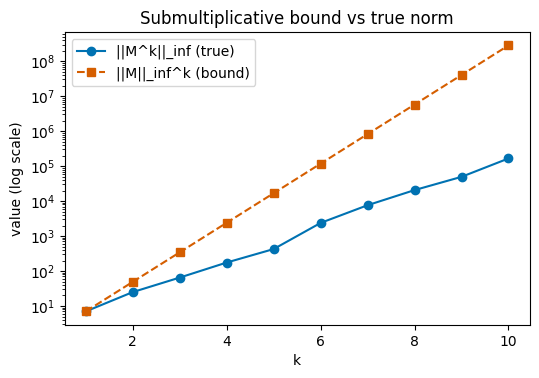

k = 10: ||M^10||_inf = 165,625, 7^10 = 282,475,249, ratio = 1,705.5


In [16]:
kk = np.arange(1, len(norm_Mk) + 1)
fig, ax = plt.subplots(figsize=(6, 3.8))
ax.semilogy(kk, norm_Mk, "o-", color=OI[0], label="||M^k||_inf (true)")
ax.semilogy(kk, bound, "s--", color=OI[1], label="||M||_inf^k (bound)")
ax.set_xlabel("k")
ax.set_ylabel("value (log scale)")
ax.set_title("Submultiplicative bound vs true norm")
ax.legend()
plt.show()
print(f"k = 10: ||M^10||_inf = {norm_Mk[9]:,.0f}, 7^10 = {bound[9]:,.0f}, ratio = {bound[9] / norm_Mk[9]:,.1f}")

**Interpret.**

(a) By $k = 10$, how many times larger is the bound than the true value?

*Sample answer.* $\|M^{10}\|_\infty = 165{,}625$ and $7^{10} = 282{,}475{,}249$: the bound is about 1,706 times larger.

(b) One sentence: is submultiplicativity useless, then?

*Sample answer.* No: it is a guarantee, not an estimate. It never fails, which is exactly what a proof needs, even when it is far from the true value.

**If time.** The cell prints $\|M^k\|_\infty^{1/k}$ for $k = 10, 50, 100, 200$. It approaches $\sqrt{10} \approx 3.162$, the absolute value of the eigenvalues of $M$ (a preview; Part 2 explains it).

Part B, Topic 9: these are the eigenvalues of M; the 2-norm ‖M‖₂ ≈ 5.117 is the largest stretch.

In [17]:
for k in (10, 50, 100, 200):
    print(f"k = {k:>3d}: ||M^k||_inf^(1/k) = {np.linalg.norm(np.linalg.matrix_power(M, k), np.inf)**(1 / k):.4f}")
print(f"sqrt(10) = {np.sqrt(10):.4f}")

k =  10: ||M^k||_inf^(1/k) = 3.3259
k =  50: ||M^k||_inf^(1/k) = 3.2170
k = 100: ||M^k||_inf^(1/k) = 3.1659
k = 200: ||M^k||_inf^(1/k) = 3.1656
sqrt(10) = 3.1623


**Takeaway.** $\|M^k\| \le \|M\|^k$ always holds, but the gap can grow very fast.

**Confidence check, Topic 4.** Mark one: Got it ☐ · Getting there ☐ · Need more practice ☐

## Topic 5. A vector iteration and its stopping test
*Mode: Run and interpret · AI use: Level 0 (AI Free) · About 12 min · builds on PS1 Ex 6*

**Goal:** run an iteration with a stopping test and compare the step size with the true error.

**Connect.** In PS1 Ex 6: the fixed point is $\bar{\mathbf{x}} = (4, 4)$, $\|G\|_\infty$ = ¾ = 0.75, so $\|\mathbf{e}^{(k)}\|_\infty \le$ (¾)$^k\,\|\mathbf{e}^{(0)}\|_\infty$, and from $\mathbf{x}^{(0)} = \mathbf{0}$ the error shrinks by exactly ¾ each step.

The inequality $\|\mathbf{x}^{(k)}\| \le \|G\|^k\,\|\mathbf{x}^{(0)}\|$ is the **convergence bound** (the Part 1 notes call it the Payoff); applied to the error $\mathbf{e}^{(k+1)} = G\mathbf{e}^{(k)}$ it gives the bound above.

**Notation.** In code, the iterate $\mathbf{x}^{(k)}$ is `x_k`, the next iterate $\mathbf{x}^{(k+1)}$ is `x_new`, and the tolerance $\tau$ is `tol`. The error is $\mathbf{e}^{(k)} = \mathbf{x}^{(k)} - \bar{\mathbf{x}}$ and the step is $\mathbf{x}^{(k+1)} - \mathbf{x}^{(k)}$.

**Predict.** When the stopping test says $\|\mathbf{x}^{(k+1)} - \mathbf{x}^{(k)}\|_\infty \le 10^{-6}$, is the true error also $\le 10^{-6}$?

*Sample answer.* Not necessarily. The test measures the step, not the distance to $\bar{\mathbf{x}}$, so the error could be larger than $\tau$.

**Run.** The toolkit function `iterate` applies $\mathbf{x}^{(k+1)} = G\mathbf{x}^{(k)} + \mathbf{c}$ until $\|\mathbf{x}^{(k+1)} - \mathbf{x}^{(k)}\|_\infty \le \tau$ and returns the history $\mathbf{x}^{(0)}, \mathbf{x}^{(1)}, \dots$. We run it from $\mathbf{x}^{(0)} = \mathbf{0}$ with $\tau = 10^{-6}$.

In [18]:
def iterate(G, c, x0, tol, maxit):
    # Run x^(k+1) = G x^(k) + c until ||x^(k+1) - x^(k)||_inf <= tol (or maxit steps).
    # Returns the array of iterates [x^(0), x^(1), ..., x^(K)]; x0 may be a vector or 0.
    x_k = np.zeros(len(c)) + x0
    history = [x_k.copy()]
    for k in range(maxit):
        x_new = G @ x_k + c
        history.append(x_new)
        if np.linalg.norm(x_new - x_k, np.inf) <= tol:
            break
        x_k = x_new
    return np.array(history)


tol = 1e-6
hist5 = iterate(G, c, 0, tol, 500)
errors5 = np.linalg.norm(hist5 - x_bar, np.inf, axis=1)        # ||e^(k)||_inf
steps5 = np.linalg.norm(np.diff(hist5, axis=0), np.inf, axis=1)  # ||x^(k+1) - x^(k)||_inf
ratios5 = errors5[1:] / errors5[:-1]

print(f"{'k':>3s} {'step ||x(k+1)-x(k)||':>22s} {'error ||e(k)||':>16s} {'ratio e(k+1)/e(k)':>19s}")
rows = list(range(5)) + list(range(len(steps5) - 3, len(steps5)))
for k in rows:
    print(f"{k:>3d} {steps5[k]:>22.3e} {errors5[k]:>16.3e} {ratios5[k]:>19.6f}")
K5 = len(hist5) - 1
print(f"\nstopped at x^({K5}): step = {steps5[-1]:.3e} <= tol = {tol:.0e}, "
      f"error = {errors5[-1]:.3e}, error/step = {errors5[-1] / steps5[-1]:.6f}")

  k   step ||x(k+1)-x(k)||   error ||e(k)||   ratio e(k+1)/e(k)
  0              1.000e+00        4.000e+00            0.750000
  1              7.500e-01        3.000e+00            0.750000
  2              5.625e-01        2.250e+00            0.750000
  3              4.219e-01        1.688e+00            0.750000
  4              3.164e-01        1.266e+00            0.750000
 47              1.342e-06        5.370e-06            0.750000
 48              1.007e-06        4.027e-06            0.750000
 49              7.551e-07        3.020e-06            0.750000

stopped at x^(50): step = 7.551e-07 <= tol = 1e-06, error = 2.265e-06, error/step = 3.000000


**Plot.** On a logarithmic vertical axis: the error $\|\mathbf{e}^{(k)}\|_\infty$ (circles, solid), the step $\|\mathbf{x}^{(k+1)} - \mathbf{x}^{(k)}\|_\infty$ (triangles, dotted), and the line (¾)$^k\cdot 4$ (dashed), with the tolerance $\tau$ as a horizontal line. The error lies exactly on the dashed line, and the step runs parallel below it, a factor of 3 smaller.

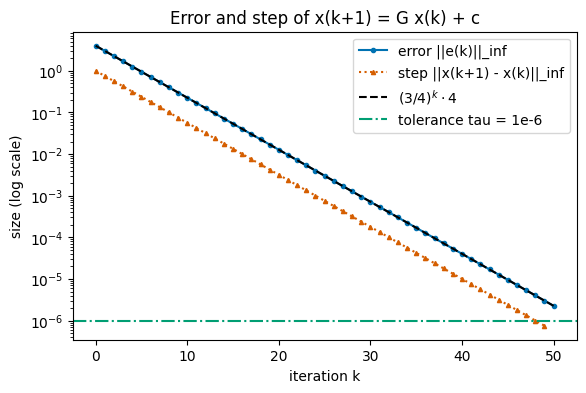

In [19]:
kk = np.arange(len(errors5))
fig, ax = plt.subplots(figsize=(6.5, 4))
ax.semilogy(kk, errors5, "o-", color=OI[0], markersize=3, label="error ||e(k)||_inf")
ax.semilogy(kk[:-1], steps5, "^:", color=OI[1], markersize=3, label="step ||x(k+1) - x(k)||_inf")
ax.semilogy(kk, 4 * 0.75**kk, "--", color=OI[6], label=r"$(3/4)^k \cdot 4$")
ax.axhline(tol, color=OI[2], linestyle="-.", label="tolerance tau = 1e-6")
ax.set_xlabel("iteration k")
ax.set_ylabel("size (log scale)")
ax.set_title("Error and step of x(k+1) = G x(k) + c")
ax.legend()
plt.show()

**Interpret.**

(a) Is the error $\le \tau$ when the test stops?

*Sample answer.* No. The test stops at $\mathbf{x}^{(50)}$ with step $7.55 \times 10^{-7} \le \tau$, but the error is $2.27 \times 10^{-6}$, about 3 times larger than $\tau$.

(b) The error is about 3 times the step. Where does 3 come from? (Hint: ¾/(1 − ¾) = 3.)

*Sample answer.* Each step the error shrinks by exactly ¾, so the step $\mathbf{e}^{(k)} - \mathbf{e}^{(k+1)}$ has size ¼ of $\|\mathbf{e}^{(k)}\|$ while the new error has size ¾ of it: error/step = ¾/(1 − ¾) = 3.

(c) Compare the stopping iteration (50) with the bound from PS1 Ex 6(e) (53).

*Sample answer.* The test stops at 50, earlier than the 53 iterations that PS1 Ex 6(e) needs to guarantee error $\le 10^{-6}$. That is consistent: at step 50 the error is still above $10^{-6}$; the bound of 53 is about the error, the test is about the step.

**Explore.** Start from $\mathbf{x}^{(0)} = (4, 0)$ instead. The cell prints the first five error ratios. One sentence: why does the starting point change the early ratios but not the bound?

In [20]:
hist5b = iterate(G, c, np.array([4.0, 0.0]), tol, 500)
errors5b = np.linalg.norm(hist5b - x_bar, np.inf, axis=1)
print("first ratios from (4, 0):", np.round(errors5b[1:6] / errors5b[:5], 4))

first ratios from (4, 0): [0.5    0.625  0.7    0.7321 0.7439]


*Sample answer.* The ratios are 0.5, 0.625, 0.7, 0.732, 0.744, approaching ¾. Now $\mathbf{e}^{(0)} = (0, -4)$ does not point along $(1, 1)$, the direction $G$ stretches most, so early steps shrink it faster; the bound $\|\mathbf{e}^{(k)}\| \le$ (¾)$^k\|\mathbf{e}^{(0)}\|$ holds for every start, and the start only changes how close the error comes to it.

‖G‖ < 1 is a guarantee, not a requirement: Topic 11 shows a G with ‖G‖∞ > 1 whose iteration still converges.

**Takeaway.** A small step is not a small error. With convergence factor $\rho$, the error can be up to $\rho/(1-\rho)$ times the last step:
$$\|\mathbf{e}^{(k+1)}\| \le \frac{\rho}{1-\rho}\,\|\mathbf{x}^{(k+1)} - \mathbf{x}^{(k)}\|.$$
Compare the Week 7 lab: a small residual was not a small error either.

**Confidence check, Topic 5.** Mark one: Got it ☐ · Getting there ☐ · Need more practice ☐

---
## Checkpoint
Good place to stop for today. Save your notebook. Topic 6 is optional; Part B starts at Topic 7.

## Topic 6 (If time). Norms of a function on a grid
*Mode: Write code · AI use: Level 0 (AI Free) · About 10 min · optional · builds on PS1 Ex 7*

**Goal:** approximate the three norms of a function from its values on a grid.

**Connect.** In PS1 Ex 7: $\|f\|_\infty = 1/4$, $\|f\|_1 = 1/6 \approx 0.1667$, $\|f\|_2 = 1/\sqrt{30} \approx 0.1826$, for $f(x) = x(1-x)$ on $[0, 1]$.

**Run (you write).** Fill in the three blanks. On $N + 1$ equally spaced points with spacing $h = (b-a)/N$, approximate $\|f\|_\infty$ by the largest $|f(x_i)|$, and the integrals by the trapezoid rule $h\left(\tfrac12 g_0 + g_1 + \cdots + g_{N-1} + \tfrac12 g_N\right)$, written out (not `np.trapz`).

In [21]:
def grid_norms(f, a, b, N):
    # Approximate ||f||_inf, ||f||_1, ||f||_2 on [a, b] from N + 1 equally spaced points
    x = np.linspace(a, b, N + 1)
    y = f(x)
    h = (b - a) / N
    norm_inf = np.max(np.abs(y))  # blank 3: the largest |f(x_i)|

    def trapezoid(g):
        # trapezoid rule for the integral of g over [a, b], written out
        return h * (np.sum(g) - 0.5 * g[0] - 0.5 * g[-1])  # blank 4: h * (sum of g, with half weight at both ends)

    norm_1 = trapezoid(np.abs(y))
    norm_2 = np.sqrt(trapezoid(y**2))  # blank 5: square root of the integral of f^2
    return norm_inf, norm_1, norm_2

**Check your work.**

In [22]:
exact6 = (0.25, 1 / 6, 1 / np.sqrt(30))
approx6 = grid_norms(f, 0, 1, 1000)
for name, a, e in zip(("||f||_inf", "||f||_1", "||f||_2"), approx6, exact6):
    assert abs(a - e) < 1e-5, f"{name}: got {a:.6f}, Problem Set 1, Ex 7 gives {e:.6f}. Check blanks 3-5."
print("Topic 6 check passed.")

Topic 6 check passed.


**Explore.** The table shows each approximation and its error for several $N$. With $N$ intervals the grid points are $x = i/N$, so $x = 1/2$ (where $f$ is largest) is a grid point exactly when $N$ is **even**.

In [23]:
print(f"{'N':>5s} {'inf-norm':>10s} {'error':>10s} {'1-norm':>10s} {'error':>10s} {'2-norm':>10s} {'error':>10s}")
for N in (2, 3, 10, 11, 100, 101, 1000):
    a_inf, a_1, a_2 = grid_norms(f, 0, 1, N)
    print(f"{N:>5d} {a_inf:>10.6f} {abs(a_inf - exact6[0]):>10.1e} {a_1:>10.6f} {abs(a_1 - exact6[1]):>10.1e}"
          f" {a_2:>10.6f} {abs(a_2 - exact6[2]):>10.1e}")

    N   inf-norm      error     1-norm      error     2-norm      error
    2   0.250000    0.0e+00   0.125000    4.2e-02   0.176777    5.8e-03
    3   0.222222    2.8e-02   0.148148    1.9e-02   0.181444    1.1e-03
   10   0.250000    0.0e+00   0.165000    1.7e-03   0.182565    9.1e-06
   11   0.247934    2.1e-03   0.165289    1.4e-03   0.182568    6.2e-06
  100   0.250000    0.0e+00   0.166650    1.7e-05   0.182574    9.1e-10
  101   0.249975    2.5e-05   0.166650    1.6e-05   0.182574    8.8e-10
 1000   0.250000    0.0e+00   0.166666    1.7e-07   0.182574    9.1e-14


**Plot.** The curve $f(x) = x(1-x)$ with its samples on two grids: $N = 3$ (squares) and $N = 4$ (circles). The $N = 4$ grid contains $x = 1/2$ and hits the maximum 1/4; the $N = 3$ grid misses it, so its largest sample is below 1/4 (dotted line).

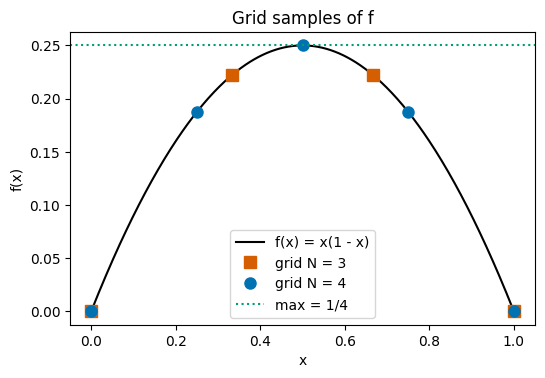

In [24]:
xs = np.linspace(0, 1, 400)
fig, ax = plt.subplots(figsize=(6, 3.8))
ax.plot(xs, f(xs), "-", color=OI[6], label="f(x) = x(1 - x)")
for N, mk, col in ((3, "s", OI[1]), (4, "o", OI[0])):
    xg = np.linspace(0, 1, N + 1)
    ax.plot(xg, f(xg), mk, color=col, markersize=8, linestyle="none", label=f"grid N = {N}")
ax.axhline(0.25, color=OI[2], linestyle=":", label="max = 1/4")
ax.set_xlabel("x")
ax.set_ylabel("f(x)")
ax.set_title("Grid samples of f")
ax.legend()
plt.show()

**Interpret.**

(a) For which $N$ is the ∞-norm approximation exact, and why?

*Sample answer.* For even $N$: then $x = 1/2$ is a grid point and the sample there is exactly $f(1/2) = 1/4$. For odd $N$ the grid straddles $1/2$ and every sample is smaller.

(b) Order the three exact values. Is it the same order as for vectors?

*Sample answer.* $\|f\|_1 \approx 0.167 < \|f\|_2 \approx 0.183 < \|f\|_\infty = 0.25$. No: it is the reverse of $\|\mathbf{x}\|_\infty \le \|\mathbf{x}\|_2 \le \|\mathbf{x}\|_1$ (PS1 Ex 7(c)). On an interval of length 1 the integrals average rather than add.

**If time.** The spike $f_k(x) = \max(0, 1 - kx)$ on $[0, 1]$ has $\|f_k\|_\infty = 1$ for every $k$, but $\|f_k\|_1 = 1/(2k) \to 0$. The table uses `grid_norms` on a fine grid. For functions, norms can disagree about "going to zero" (the Part 1 notes: norms of functions).

In [25]:
print(f"{'k':>5s} {'||f_k||_inf':>12s} {'||f_k||_1':>12s} {'||f_k||_2':>12s}")
for k in (1, 10, 100, 1000):
    spike = lambda x, k=k: np.maximum(0.0, 1 - k * x)
    a_inf, a_1, a_2 = grid_norms(spike, 0, 1, 100_000)
    print(f"{k:>5d} {a_inf:>12.4f} {a_1:>12.6f} {a_2:>12.6f}")

    k  ||f_k||_inf    ||f_k||_1    ||f_k||_2
    1       1.0000     0.500000     0.577350
   10       1.0000     0.050000     0.182574
  100       1.0000     0.005000     0.057735
 1000       1.0000     0.000500     0.018258


**Takeaway.** Function norms are vector norms of samples, in the limit of a fine grid: $\max_i |f(x_i)| \to \|f\|_\infty$, and the trapezoid sums $\to \|f\|_1$ and $\|f\|_2^2$.

**Confidence check, Topic 6.** Mark one: Got it ☐ · Getting there ☐ · Need more practice ☐

---
# Part B. Measuring Sensitivity
Topics 7–12 build on **Problem Set 2**.

## Topic 7. κ against ε, and the error bound on many perturbations
*Mode: Run and interpret, with an optional AI-assisted task · AI use: Level 2 (AI Collaboration) for the optional part; Level 0 otherwise · About 12 min · builds on PS2 Ex 1–2*

**Goal:** compute κ∞ for a family of nearly singular matrices and check the error bound on 1000 perturbations.

**Connect.** In PS2 Ex 2: $\kappa_\infty(A_\varepsilon) = (2 + \varepsilon)^2/\varepsilon$, so $\kappa_\infty(A_{0.01}) = 404.01$; changing $\mathbf{b} = (2, 2.01)$ to $(2, 2.02)$ moved $\mathbf{x}$ from $(1, 1)$ to $(0, 2)$. In PS2 Ex 1 you proved $\|\Delta\mathbf{x}\|/\|\mathbf{x}\| \le \kappa\,\|\Delta\mathbf{b}\|/\|\mathbf{b}\|$.

**Optional task (AI-assisted, Level 2).** Ask your assistant for code that computes $\kappa_\infty(A_\varepsilon)$ with `np.linalg.cond(A, np.inf)` for $\varepsilon = 10^{-1}, \dots, 10^{-8}$, prints a table next to $(2 + \varepsilon)^2/\varepsilon$, and plots κ against ε on log-log axes. A suggested prompt:

> Write Python code with NumPy. For eps = 1e-1, 1e-2, …, 1e-8, let A = [[1, 1], [1, 1 + eps]] (as a float array) and compute its infinity-norm condition number with `np.linalg.cond(A, np.inf)`. Store the eps values in a list `eps_list` and the condition numbers in a list `kappa_list`. Print a table with columns eps, the computed condition number, and the formula (2 + eps)**2 / eps, and plot the condition number against eps on log-log axes.

If you skip this task, leave the next cell empty: the given cell after it supplies the same lists.

In [26]:
# Optional: AI-assisted (key version of what the assistant should produce)
eps_list = [10.0**(-j) for j in range(1, 9)]
kappa_list = [np.linalg.cond(A_eps(eps), np.inf) for eps in eps_list]
print(f"{'eps':>8s} {'cond(A, inf)':>18s} {'(2+eps)^2/eps':>18s}")
for eps, kap in zip(eps_list, kappa_list):
    print(f"{eps:>8.0e} {kap:>18.4f} {(2 + eps)**2 / eps:>18.4f}")

     eps       cond(A, inf)      (2+eps)^2/eps
   1e-01            44.1000            44.1000
   1e-02           404.0100           404.0100
   1e-03          4004.0010          4004.0010
   1e-04         40004.0001         40004.0001
   1e-05        400004.0000        400004.0000
   1e-06       4000004.0003       4000004.0000
   1e-07      40000003.9766      40000004.0000
   1e-08     400000006.4310     400000004.0000


**Disclosure (only if you used the optional cell).** Tool used: … · Prompt: … · What I changed in the generated code, and why: …

*Sample answer.* Key version written by hand; no tool used. (A student who used an assistant fills in the tool, the prompt, and every change made, for example adding `np.inf` to `np.linalg.cond`.)

**Given.** This cell defines `eps_list` and `kappa_list` **only if** the optional cell did not.

In [27]:
if "eps_list" not in globals() or "kappa_list" not in globals():
    eps_list = [10.0**(-j) for j in range(1, 9)]
    kappa_list = [np.linalg.cond(A_eps(eps), np.inf) for eps in eps_list]
    print("Using the given code for eps_list and kappa_list.")
else:
    print("Using eps_list and kappa_list from the optional cell.")

Using eps_list and kappa_list from the optional cell.


**Verify (required).** Compare with the hand answers of Problem Set 2, Ex 2. (At ε = 10⁻⁸, `cond` differs from the formula in the ninth digit because of rounding; the check allows that.)

In [28]:
msg = "Your code disagrees with Problem Set 2, Ex 2. Find out why before going on."
eps_arr = np.array(eps_list, dtype=float)
kappa_arr = np.array(kappa_list, dtype=float)
i01 = int(np.argmin(np.abs(eps_arr - 0.01)))
assert np.isclose(eps_arr[i01], 0.01) and abs(kappa_arr[i01] - 404.01) <= 1e-6, msg
assert np.allclose(kappa_arr, (2 + eps_arr)**2 / eps_arr, rtol=1e-7, atol=0), msg
small = eps_arr <= 0.01 * (1 + 1e-12)
slope7 = np.polyfit(np.log10(eps_arr[small]), np.log10(kappa_arr[small]), 1)[0]
assert abs(slope7 + 1) <= 0.01, msg
print(f"kappa at eps = 0.01: {kappa_arr[i01]:.6f};  log-log slope for eps <= 1e-2: {slope7:.4f}")
print("Topic 7 verify passed.")

kappa at eps = 0.01: 404.010000;  log-log slope for eps <= 1e-2: -0.9995
Topic 7 verify passed.


**Plot.** $\kappa_\infty(A_\varepsilon)$ against $\varepsilon$ on log-log axes: computed values (circles) and the formula $(2+\varepsilon)^2/\varepsilon$ (dashed line). The points lie on the line, a straight line of slope −1: each factor of 10 smaller in ε makes κ ten times larger.

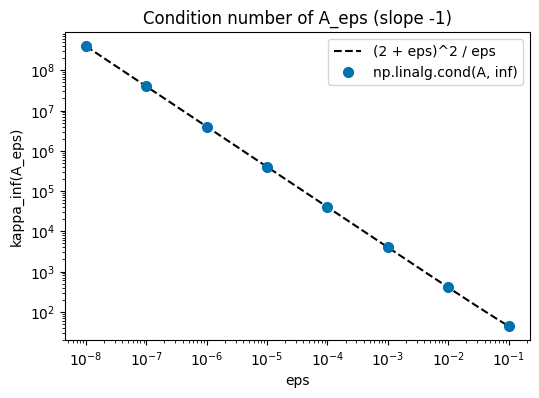

In [29]:
fig, ax = plt.subplots(figsize=(6, 4))
ee = np.logspace(-8, -1, 100)
ax.loglog(ee, (2 + ee)**2 / ee, "--", color=OI[6], label="(2 + eps)^2 / eps")
ax.loglog(eps_arr, kappa_arr, "o", color=OI[0], markersize=7, label="np.linalg.cond(A, inf)")
ax.set_xlabel("eps")
ax.set_ylabel("kappa_inf(A_eps)")
ax.set_title("Condition number of A_eps (slope -1)")
ax.legend()
plt.show()

**Predict (before Run 2).** We will perturb $\mathbf{b} = (2, 2.01)$ in 1000 random directions. Will any perturbation be amplified by more than 404? About how close will the worst one come?

*Sample answer.* None can exceed κ = 404.01, because the bound is a theorem (PS2 Ex 1(f)). In two dimensions the worst of 1000 random directions should come close, perhaps within a few percent.

**Run 2.** With $A = A_{0.01}$ and $\mathbf{b} = (2, 2.01)$, draw 1000 perturbations $\Delta\mathbf{b}$ uniform in $[-1, 1]^2$ (seed 3515), scale each to $\|\Delta\mathbf{b}\|_\infty = 10^{-6}$, and compute the amplification $\dfrac{\|\Delta\mathbf{x}\|_\infty/\|\mathbf{x}\|_\infty}{\|\Delta\mathbf{b}\|_\infty/\|\mathbf{b}\|_\infty}$.

In [30]:
A7 = A_eps(0.01)
b7 = np.array([2.0, 2.01])
x7 = np.linalg.solve(A7, b7)
kappa7 = np.linalg.cond(A7, np.inf)


def amplification(db):
    dx = np.linalg.solve(A7, b7 + db) - x7
    rel_x = np.linalg.norm(dx, np.inf) / np.linalg.norm(x7, np.inf)
    rel_b = np.linalg.norm(db, np.inf) / np.linalg.norm(b7, np.inf)
    return rel_x / rel_b


rng7 = np.random.default_rng(3515)
db_all = rng7.uniform(-1, 1, size=(1000, 2))
db_all = 1e-6 * db_all / np.abs(db_all).max(axis=1, keepdims=True)   # ||db||_inf = 1e-6
amp7 = np.array([amplification(db) for db in db_all])

show("kappa_inf(A)", kappa7)
show("max amplification", f"{amp7.max():.2f}  ({amp7.max() / kappa7:.4f} kappa)")
show("median amplification", f"{np.median(amp7):.2f}  ({np.median(amp7) / kappa7:.3f} kappa)")
show("fraction above kappa/2", f"{np.mean(amp7 > kappa7 / 2):.1%}")
show("any above kappa?", bool(np.any(amp7 > kappa7 * (1 + 1e-9))))

kappa_inf(A)                     404.0099999999996
max amplification                403.98  (0.9999 kappa)
median amplification             209.72  (0.519 kappa)
fraction above kappa/2           51.7%
any above kappa?                 False


**Plot.** Histogram of the 1000 amplification factors. The dashed line marks κ = 404.01 and the dotted line κ/2. No bar lies to the right of the dashed line, and about half of the values are above κ/2.

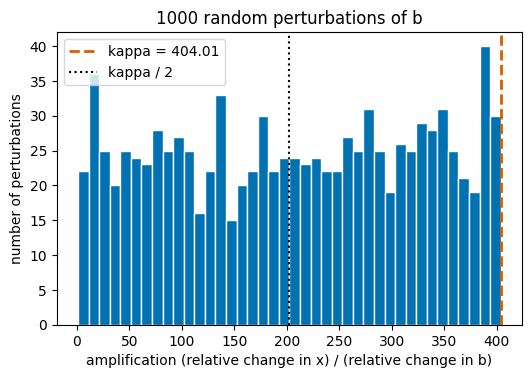

In [31]:
fig, ax = plt.subplots(figsize=(6, 3.8))
ax.hist(amp7, bins=40, color=OI[0], edgecolor="white")
ax.axvline(kappa7, color=OI[1], linestyle="--", linewidth=2, label="kappa = 404.01")
ax.axvline(kappa7 / 2, color=OI[6], linestyle=":", label="kappa / 2")
ax.set_xlabel("amplification (relative change in x) / (relative change in b)")
ax.set_ylabel("number of perturbations")
ax.set_title("1000 random perturbations of b")
ax.legend()
plt.show()

**Interpret.**

(a) True or false, with a reason: "The bound is so pessimistic it is useless."

*Sample answer.* False. The worst of the 1000 perturbations reaches 403.98, that is 0.9999 κ, the median is about 0.52 κ, and about 52% are above κ/2. In ℝ² the bound is nearly reached.

(b) Which direction of $\Delta\mathbf{b}$ is amplified most? Hint: the eigenvectors of $A^{-1}$, or just try $\Delta\mathbf{b} \propto (1, -1)$ versus $(1, 1)$ in the next cell.

*Sample answer.* $\Delta\mathbf{b} \propto (1, -1)$: $A^{-1}(1, -1) = (201, -200)$, so the amplification is exactly κ = 404.01. For $(1, 1)$, $A^{-1}(1, 1) = (1, 0)$ and the amplification is only 2.01.

In [32]:
for direction in ([1.0, -1.0], [1.0, 1.0]):
    db = 1e-6 * np.array(direction)
    print(f"db along {tuple(direction)}: amplification = {amplification(db):.2f}")

db along (1.0, -1.0): amplification = 404.01
db along (1.0, 1.0): amplification = 2.01


**Takeaway.** κ is the worst-case amplification of relative errors in b. In ℝ², random perturbations often come close to it:
$$\frac{\|\Delta\mathbf{x}\|}{\|\mathbf{x}\|} \le \kappa(A)\,\frac{\|\Delta\mathbf{b}\|}{\|\mathbf{b}\|}.$$

**Confidence check, Topic 7.** Mark one: Got it ☐ · Getting there ☐ · Need more practice ☐

## Topic 8. κ explains the Week 7 error table
*Mode: Run and interpret · AI use: Level 0 (AI Free) · About 10 min · builds on PS2 Ex 3*

**Goal:** predict the digits lost when solving Hilbert systems, and see when a computed κ cannot be trusted.

**Connect.** In PS2 Ex 3 you predicted digits lost as $\log_{10}\kappa_2(H_n)$ and found that for $n \ge 12$ no digit is guaranteed.

**Run.** For $n = 2, 4, \dots, 14$ we solve $H_n\hat{\mathbf{x}} = H_n\mathbf{1}$ with `np.linalg.solve`, so the exact solution is $\mathbf{x} = (1, \dots, 1)$. The exact $\kappa_2$ comes from the toolkit function `hilbert_cond_exact`, which uses the closed-form integer inverse
$$(H_n^{-1})_{ij} = (-1)^{i+j}(i+j-1)\binom{n+i-1}{n-j}\binom{n+j-1}{n-i}\binom{i+j-2}{i-1}^2 \quad (1\text{-based}),$$
and then $\kappa_2 = \lambda_{\max}(H_n)\,\lambda_{\max}(H_n^{-1})$. The table compares it with `np.linalg.cond(H)`.

In [33]:
def hilbert_cond_exact(n):
    # Exact 2-norm condition number of the Hilbert matrix H_n.
    # The inverse is built from the closed-form integer formula with Python integers
    # (math.comb is exact; NumPy int64 would overflow for larger n), then converted to
    # float. kappa_2 = lambda_max(H_n) * lambda_max(H_n^{-1}): only the two largest
    # eigenvalues are computed in floating point, and those are computed accurately.
    inv = np.array([[float((-1)**(i + j) * (i + j - 1) * math.comb(n + i - 1, n - j)
                           * math.comb(n + j - 1, n - i) * math.comb(i + j - 2, i - 1)**2)
                     for j in range(1, n + 1)] for i in range(1, n + 1)])
    return np.linalg.eigvalsh(hilbert(n))[-1] * np.linalg.eigvalsh(inv)[-1]


ns8 = list(range(2, 15, 2))
kappa_exact8, kappa_np8, err8, res8 = [], [], [], []
for n in ns8:
    H = hilbert(n)
    x = np.ones(n)
    b = H @ x
    xhat = np.linalg.solve(H, b)
    kappa_exact8.append(hilbert_cond_exact(n))
    kappa_np8.append(np.linalg.cond(H))
    err8.append(np.linalg.norm(x - xhat, np.inf))
    res8.append(np.linalg.norm(b - H @ xhat, np.inf))

print(f"{'n':>3s} {'exact kappa_2':>14s} {'np.linalg.cond':>15s} {'kappa_2*eps':>12s} "
      f"{'error':>9s} {'residual':>9s} {'digits lost':>12s}")
for n, ke, kn, e, r in zip(ns8, kappa_exact8, kappa_np8, err8, res8):
    print(f"{n:>3d} {ke:>14.3e} {kn:>15.3e} {ke * eps_mach:>12.1e} {e:>9.1e} {r:>9.1e} {np.log10(ke):>12.1f}")

  n  exact kappa_2  np.linalg.cond  kappa_2*eps     error  residual  digits lost
  2      1.928e+01       1.928e+01      4.3e-15   5.6e-16   0.0e+00          1.3
  4      1.551e+04       1.551e+04      3.4e-12   5.0e-14   0.0e+00          4.2
  6      1.495e+07       1.495e+07      3.3e-09   2.3e-10   1.1e-16          7.2
  8      1.526e+10       1.526e+10      3.4e-06   1.6e-07   4.4e-16         10.2
 10      1.603e+13       1.603e+13      3.6e-03   7.4e-04   4.4e-16         13.2
 12      1.713e+16       1.719e+16      3.8e+00   2.2e-01   4.4e-16         16.2
 14      1.853e+19       4.049e+17      4.1e+03   8.2e+00   4.4e-16         19.3


**Note.** The errors from `np.linalg.solve` depend on the LAPACK library your NumPy uses, so your numbers may differ from a classmate's; only the orders of magnitude should match. They also differ from the Week 7 lab solver's numbers (7e-16, 1.5e-13, …, 57), which the notes quote. The exact κ₂ column does not depend on the machine.

**Plot.** On a logarithmic vertical axis, against $n$: the observed error $\|\mathbf{x} - \hat{\mathbf{x}}\|_\infty$ (circles, solid) and the prediction $\kappa_2\varepsilon_{\text{mach}}$ (squares, dashed). Both climb steadily; the error stays one to three orders of magnitude below the prediction.

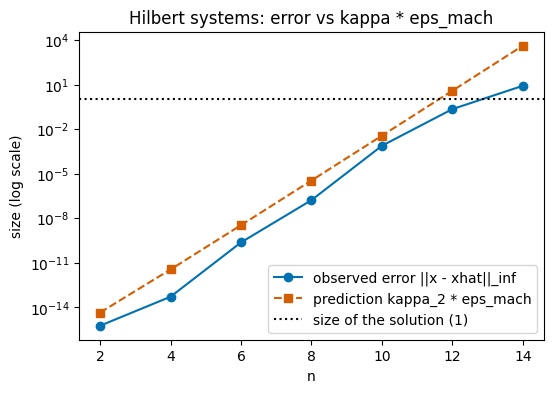

In [34]:
fig, ax = plt.subplots(figsize=(6, 4))
ax.semilogy(ns8, err8, "o-", color=OI[0], label="observed error ||x - xhat||_inf")
ax.semilogy(ns8, np.array(kappa_exact8) * eps_mach, "s--", color=OI[1], label="prediction kappa_2 * eps_mach")
ax.axhline(1, color=OI[6], linestyle=":", label="size of the solution (1)")
ax.set_xlabel("n")
ax.set_ylabel("size (log scale)")
ax.set_title("Hilbert systems: error vs kappa * eps_mach")
ax.legend()
plt.show()

**Interpret.**

(a) For which $n$ does the error stay below $\kappa_2\varepsilon_{\text{mach}}$?

*Sample answer.* For every $n$ in the table, by one to three orders of magnitude. The prediction is a rule of thumb for the worst case, not an exact count.

(b) Why does `np.linalg.cond` underestimate $\kappa_2$ for $n = 14$? (PS2 Ex 3(d).)

*Sample answer.* $\kappa_2 = \sigma_{\max}/\sigma_{\min}$, and the true $\sigma_{\min}(H_{14}) \approx \sigma_{\max}/(1.85 \times 10^{19})$ is far below the rounding errors, about $\varepsilon_{\text{mach}}\sigma_{\max}$, made while computing the singular values. The computed $\sigma_{\min}$ is rounding noise, so the computed κ comes out far below the exact $1.85 \times 10^{19}$.

(c) One sentence: does the tiny residual mean the solver failed?

*Sample answer.* No: a residual near $10^{-16}$ shows the solver did its job (it solved a nearby problem); the large error comes from the problem's sensitivity, κ.

**Takeaway.** Digits lost ≈ log₁₀κ. Once κ ≳ 1/ε_mach, neither the solution nor a computed κ can be trusted:
$$\frac{\|\mathbf{x} - \hat{\mathbf{x}}\|}{\|\mathbf{x}\|} \lesssim \kappa(A)\,\varepsilon_{\text{mach}}.$$

**Confidence check, Topic 8.** Mark one: Got it ☐ · Getting there ☐ · Need more practice ☐

## Topic 9. The unit circle becomes an ellipse
*Mode: Run and interpret · AI use: Level 0 (AI Free) · About 8 min · builds on PS2 Ex 4*

**Goal:** see the singular values of M as the semi-axes of the image of the unit circle.

**Connect.** In PS2 Ex 4: $\sigma_1 = \sqrt{15 + 5\sqrt5} \approx 5.117$ and $\sigma_2 = \sqrt{15 - 5\sqrt5} \approx 1.954$ for $M$, so $\|M\|_2 \approx 5.117$ and $\kappa_2(M) \approx 2.618$.

**Predict.** Sketch the image of the unit circle under $M$. How long are its longest and shortest semi-axes?

*Sample answer.* An ellipse, tilted, with longest semi-axis about 5.117 ($\sigma_1$) and shortest about 1.954 ($\sigma_2$).

**Run.** Take 2000 equally spaced points on the unit circle $\|\mathbf{x}\|_2 = 1$, map them by $M$, and compare the largest and smallest $\|M\mathbf{x}\|_2$ with the singular values from `np.linalg.svd`.

**Plot (same cell).** The unit circle (dashed) and its image under the matrix (solid), with equal aspect ratio. The two arrows from the origin are the semi-axes $\sigma_1\mathbf{u}_1$ and $\sigma_2\mathbf{u}_2$ from the SVD, labeled with their lengths; they end exactly on the ellipse, at its farthest and nearest points.

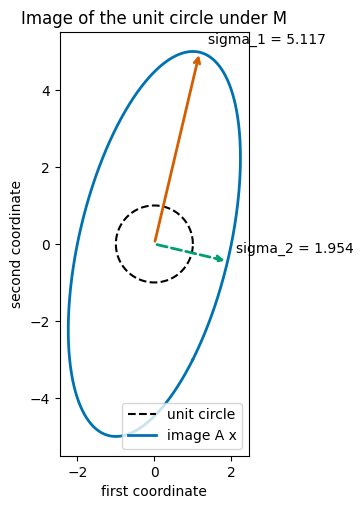

max ||M x||_2 over samples       5.11667
min ||M x||_2 over samples       1.95440
singular values                  [5.1167 1.9544]
kappa_2(M) = sigma_1/sigma_2     2.6180


In [35]:
def circle_image(A, title):
    theta = np.linspace(0, 2 * np.pi, 2000, endpoint=False)
    circle = np.vstack([np.cos(theta), np.sin(theta)])     # columns have ||x||_2 = 1
    image = A @ circle
    stretch = np.linalg.norm(image, axis=0)                # ||A x||_2 for each point
    U, sigma, Vt = np.linalg.svd(A)
    fig, ax = plt.subplots(figsize=(5.5, 5.5))
    ax.plot(circle[0], circle[1], "--", color=OI[6], label="unit circle")
    ax.plot(image[0], image[1], "-", color=OI[0], linewidth=2, label="image A x")
    for i, (col, ls) in enumerate(((OI[1], "-"), (OI[2], "--"))):
        tip = sigma[i] * U[:, i]
        ax.annotate("", xy=tip, xytext=(0, 0),
                    arrowprops=dict(arrowstyle="->", color=col, linewidth=2, linestyle=ls))
        ax.annotate(f"sigma_{i + 1} = {sigma[i]:.3f}", tip, textcoords="offset points", xytext=(6, 6))
    ax.set_aspect("equal")
    ax.set_xlabel("first coordinate")
    ax.set_ylabel("second coordinate")
    ax.set_title(title)
    ax.legend(loc="best")
    plt.show()
    return stretch, sigma


stretch9, sigma9 = circle_image(M, "Image of the unit circle under M")
show("max ||M x||_2 over samples", f"{stretch9.max():.5f}")
show("min ||M x||_2 over samples", f"{stretch9.min():.5f}")
show("singular values", np.round(sigma9, 5))
show("kappa_2(M) = sigma_1/sigma_2", f"{sigma9[0] / sigma9[1]:.4f}")

**Interpret.**

(a) Read $\|M\|_2$ off the plot.

*Sample answer.* About 5.12, the length of the longest semi-axis.

(b) Multiple choice: $\kappa_2$ measures (the area / how flat the ellipse is / the angle of the ellipse).

*Sample answer.* How flat the ellipse is: $\kappa_2 = \sigma_1/\sigma_2$, the ratio of the longest to the shortest semi-axis.

(c) Compare $\|M\|_2$ with $\|M\|_1 = 6$ and $\|M\|_\infty = 7$.

*Sample answer.* $\|M\|_2 \approx 5.117$ is smaller than both, and below $\sqrt{\|M\|_1\|M\|_\infty} = \sqrt{42} \approx 6.48$ (PS2 Ex 4(d)). Also $|\lambda| = \sqrt{10} \approx 3.162 \le \|M\|_2$ for the eigenvalues of $M$ (PS2 Ex 4(e)).

**Explore.** Replace $M$ with $C = \begin{pmatrix}3 & 0\\ 4 & 5\end{pmatrix}$ and with the singular matrix $\begin{pmatrix}1 & 2\\ 2 & 4\end{pmatrix}$. Describe what the singular matrix does to the circle.

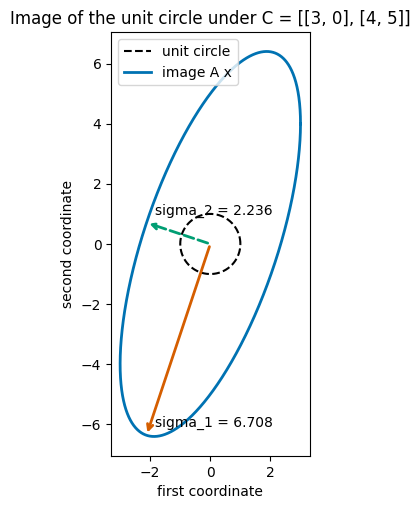

C = [[3, 0], [4, 5]]: sigma_1 = 6.7082, sigma_2 = 2.236e+00, kappa_2 = 3


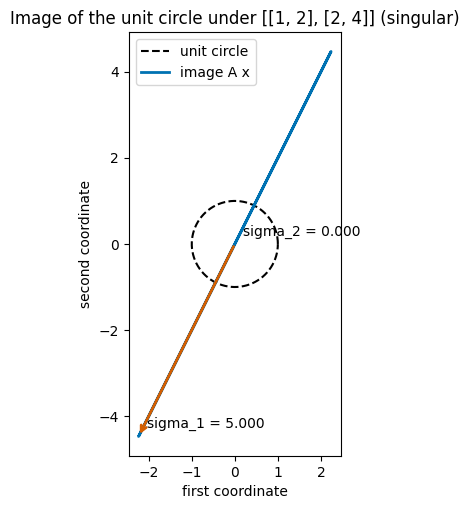

[[1, 2], [2, 4]] (singular): sigma_1 = 5.0000, sigma_2 = 1.814e-16, kappa_2 = 2.756e+16


In [36]:
for A9, name in ((np.array([[3.0, 0.0], [4.0, 5.0]]), "C = [[3, 0], [4, 5]]"),
                 (np.array([[1.0, 2.0], [2.0, 4.0]]), "[[1, 2], [2, 4]] (singular)")):
    _, s = circle_image(A9, f"Image of the unit circle under {name}")
    print(f"{name}: sigma_1 = {s[0]:.4f}, sigma_2 = {s[1]:.3e}, kappa_2 = {s[0] / s[1]:.4g}")

*Sample answer.* For $C$: $\sigma = 6.708, 2.236$ (that is $3\sqrt5$ and $\sqrt5$), so $\kappa_2(C) = 3$. The singular matrix squashes the circle onto a line segment of half-length 5 along the direction $(1, 2)$: $\sigma_2$ is about $10^{-16}$, rounding noise for 0, so the "ellipse" has no width and $\kappa_2$ is huge (really ∞).

**Takeaway.** ‖A‖₂ = σ_max and κ₂ = σ_max/σ_min: the 2-norm and the condition number are the longest semi-axis and the flatness of the image ellipse.

**Confidence check, Topic 9.** Mark one: Got it ☐ · Getting there ☐ · Need more practice ☐

## Topic 10. Cholesky from the hand steps
*Mode: Run and interpret · AI use: Level 0 (AI Free) · About 8 min · builds on PS2 Ex 5*

**Goal:** run a Cholesky factorization written from the hand steps, use it to solve a system, and use it as a test.

**Connect.** In PS2 Ex 5: $K = LL^T$ with $L = \begin{pmatrix}2&0&0\\-1&2&0\\0&-1&2\end{pmatrix}$; with $\mathbf{b} = (2, 1, 3)$ the solution is $(1, 1, 1)$; $\begin{pmatrix}1&2\\2&3\end{pmatrix}$ fails at $\sqrt{3 - 4}$.

**Run.** `cholesky` and `solve_cholesky` are given complete. Read them next to your hand steps, then run the cells.

*Optional:* compare the loop with the hand steps of Problem Set 2, Ex. 5.

In [37]:
def cholesky(A):
    # Cholesky factor L (lower triangular, positive diagonal) with A = L L^T.
    # Works column by column, as in Problem Set 2, Ex 5. Raises ValueError if A is not SPD.
    A = np.asarray(A, dtype=float)
    n = A.shape[0]
    L = np.zeros((n, n))
    for j in range(n):
        d = A[j, j] - L[j, :j] @ L[j, :j]                          # remaining diagonal
        if d <= 0:
            raise ValueError("matrix is not positive definite")
        L[j, j] = np.sqrt(d)
        for i in range(j + 1, n):
            L[i, j] = (A[i, j] - L[i, :j] @ L[j, :j]) / L[j, j]   # divide by the column's diagonal
    return L


def solve_cholesky(A, b):
    # Solve A x = b for SPD A: A = L L^T, then L y = b (forward), then L^T x = y (back).
    L = cholesky(A)
    b = np.asarray(b, dtype=float)
    n = len(b)
    y = np.zeros(n)
    for i in range(n):                                   # forward substitution
        y[i] = (b[i] - L[i, :i] @ y[:i]) / L[i, i]
    x = np.zeros(n)
    for i in range(n - 1, -1, -1):                       # back substitution with L^T
        x[i] = (y[i] - L[i + 1:, i] @ x[i + 1:]) / L[i, i]
    return x


print("cholesky(K) =\n", cholesky(K))
print("solve_cholesky(K, (2, 1, 3)) =", solve_cholesky(K, [2.0, 1.0, 3.0]))
L6 = cholesky(hilbert(6))
print("diagonal of cholesky(hilbert(6)) =", L6.diagonal())
try:
    cholesky([[1.0, 2.0], [2.0, 3.0]])
except ValueError as err:
    print("cholesky([[1, 2], [2, 3]]) raised ValueError:", err)

cholesky(K) =
 [[ 2.  0.  0.]
 [-1.  2.  0.]
 [ 0. -1.  2.]]
solve_cholesky(K, (2, 1, 3)) = [1. 1. 1.]
diagonal of cholesky(hilbert(6)) = [1.     0.2887 0.0745 0.0189 0.0048 0.0012]
cholesky([[1, 2], [2, 3]]) raised ValueError: matrix is not positive definite


**Check.** These checks confirm the code against Problem Set 2, Ex 5 and NumPy.

In [38]:
L_ps2 = np.array([[2.0, 0, 0], [-1, 2, 0], [0, -1, 2]])
assert np.allclose(cholesky(K), L_ps2, atol=1e-12, rtol=0), "cholesky(K) should be the L of Problem Set 2, Ex 5."
assert np.allclose(cholesky(K), np.linalg.cholesky(K), atol=1e-12), "cholesky(K) should match np.linalg.cholesky(K)."
assert np.allclose(solve_cholesky(K, [2, 1, 3]), [1, 1, 1], atol=1e-12, rtol=0), "solve_cholesky(K, b) should be (1, 1, 1)."
try:
    cholesky([[1.0, 2.0], [2.0, 3.0]])
    raise AssertionError("cholesky([[1, 2], [2, 3]]) should raise ValueError: the matrix is not SPD.")
except ValueError:
    pass
H6 = hilbert(6)
assert np.linalg.norm(L6 @ L6.T - H6) <= 1e-12 * np.linalg.norm(H6), "L L^T should reproduce hilbert(6)."
print("Topic 10 check passed.")

Topic 10 check passed.


For Interpret (a), this cell runs `np.linalg.cholesky` on $\begin{pmatrix}1&2\\2&3\end{pmatrix}$ and prints the name of the error instead of stopping the notebook.

In [39]:
try:
    np.linalg.cholesky(np.array([[1.0, 2.0], [2.0, 3.0]]))
except Exception as err:
    print(f"{type(err).__name__}: {err}")

LinAlgError: Matrix is not positive definite


**Interpret.**

(a) What does `np.linalg.cholesky` do on $\begin{pmatrix}1&2\\2&3\end{pmatrix}$? Name the error.

*Sample answer.* It raises `LinAlgError: Matrix is not positive definite`, the same verdict as our `ValueError`.

(b) True or false, with a reason: "Every symmetric matrix with positive diagonal has a Cholesky factorization."

*Sample answer.* False. $\begin{pmatrix}1&2\\2&3\end{pmatrix}$ is symmetric with positive diagonal, but Cholesky fails at $\sqrt{3 - 4}$, and $\mathbf{x} = (2, -1)$ gives $\mathbf{x}^T A\mathbf{x} = -1 < 0$. A positive diagonal is necessary, not sufficient.

**Explore.** The cell times `solve_cholesky` against `np.linalg.solve` (LU, in compiled LAPACK) for $n = 100, 200, 400$ on random SPD matrices $B^TB + nI$ (seed 3515). Is the loop slower than NumPy?

In [40]:
rng10 = np.random.default_rng(3515)
print(f"{'n':>4s} {'solve_cholesky (s)':>19s} {'np.linalg.solve (s)':>20s} {'max difference':>15s}")
for n in (100, 200, 400):
    B = rng10.standard_normal((n, n))
    A10 = B.T @ B + n * np.eye(n)
    b10 = np.ones(n)
    t0 = time.perf_counter()
    x_chol = solve_cholesky(A10, b10)
    t1 = time.perf_counter()
    x_lu = np.linalg.solve(A10, b10)
    t2 = time.perf_counter()
    print(f"{n:>4d} {t1 - t0:>19.4f} {t2 - t1:>20.5f} {np.abs(x_chol - x_lu).max():>15.1e}")

   n  solve_cholesky (s)  np.linalg.solve (s)  max difference
 100              0.0088              0.00018         1.0e-17
 200              0.0334              0.00027         9.5e-18


 400              0.1343              0.00097         6.1e-18

*Sample answer.* Yes, much slower: NumPy runs compiled LAPACK code, while our loop runs in Python. Both give the same solution to rounding level. The point of Cholesky is its operation count, about n³/3 against 2n³/3 for LU, not the speed of a Python loop.

**Takeaway.** Cholesky is LU for SPD matrices, with half the work and no pivoting. It is also a test: it breaks down exactly when the matrix is not SPD.
$$A = LL^T \iff A \text{ is SPD} \qquad (\text{about } n^3/3 \text{ flops}).$$

**Toolkit.** `cholesky` and `solve_cholesky` are added to the project toolkit at the end.

**Confidence check, Topic 10.** Mark one: Got it ☐ · Getting there ☐ · Need more practice ☐

## Topic 11 (If time). A norm bigger than 1 that still converges
*Mode: Run and interpret · AI use: Level 0 (AI Free) · About 8 min · optional · builds on PS2 Ex 6*

**Goal:** see an iteration converge although ‖G‖∞ > 1, and connect the rate to the eigenvalues.

**Connect.** In PS2 Ex 6: ‖G₂‖∞ = 3/2, but ‖G₂ᵏ‖∞ = (2k + 1)/2ᵏ: 3/2, 5/4, 7/8, 9/16, 11/32, … → 0; both eigenvalues are ½. Here $G_2 = \begin{pmatrix}½ & 1\\ 0 & ½\end{pmatrix}$.

**Run.** A table of $\|G_2^k\|_\infty$, the formula $(2k+1)/2^k$, and the convergence bound factor $(3/2)^k$. Then the iteration $\mathbf{x}^{(k+1)} = G_2\mathbf{x}^{(k)} + \mathbf{c}$ with `iterate` from Topic 5, $\mathbf{c} = (1, 1)$, $\mathbf{x}^{(0)} = \mathbf{0}$, $\tau = 10^{-6}$.

In [41]:
norms_G2k = [np.linalg.norm(np.linalg.matrix_power(G2, k), np.inf) for k in range(1, 11)]
print(f"{'k':>3s} {'||G2^k||_inf':>13s} {'(2k+1)/2^k':>12s} {'(3/2)^k':>9s}")
for k, nk in zip(range(1, 11), norms_G2k):
    print(f"{k:>3d} {nk:>13.6f} {(2 * k + 1) / 2**k:>12.6f} {1.5**k:>9.3f}")

hist11 = iterate(G2, c, 0, 1e-6, 200)
x_bar11 = np.linalg.solve(np.eye(2) - G2, c)          # fixed point (I - G2)^(-1) c
errors11 = np.linalg.norm(hist11 - x_bar11, np.inf, axis=1)
print(f"\nfixed point (I - G2)^(-1) c = {x_bar11}")
print(f"stopped after {len(hist11) - 1} steps at {hist11[-1]}, error {errors11[-1]:.1e}")
print("last error ratios:", np.round(errors11[-4:] / errors11[-5:-1], 4))
print("eigenvalues of G2:", np.linalg.eigvals(G2))

  k  ||G2^k||_inf   (2k+1)/2^k   (3/2)^k
  1      1.500000     1.500000     1.500
  2      1.250000     1.250000     2.250
  3      0.875000     0.875000     3.375
  4      0.562500     0.562500     5.062
  5      0.343750     0.343750     7.594
  6      0.203125     0.203125    11.391
  7      0.117188     0.117188    17.086
  8      0.066406     0.066406    25.629
  9      0.037109     0.037109    38.443
 10      0.020508     0.020508    57.665

fixed point (I - G2)^(-1) c = [6. 2.]
stopped after 27 steps at [6. 2.], error 8.5e-07
last error ratios: [0.5204 0.5196 0.5189 0.5182]
eigenvalues of G2: [0.5 0.5]


**Plot.** On a logarithmic vertical axis: the error $\|\mathbf{x}^{(k)} - \bar{\mathbf{x}}\|_\infty$ of the $G_2$ iteration (circles, solid), the line $(½)^k\cdot\|\mathbf{e}^{(0)}\|_\infty$ (dotted), and the convergence bound $(3/2)^k\,\|\mathbf{e}^{(0)}\|_\infty$ (dashed), which grows. The error falls steadily, a little more slowly than the ½ line (because of the $k\,2^{1-k}$ term in $G_2^k$), while the bound climbs off the top.

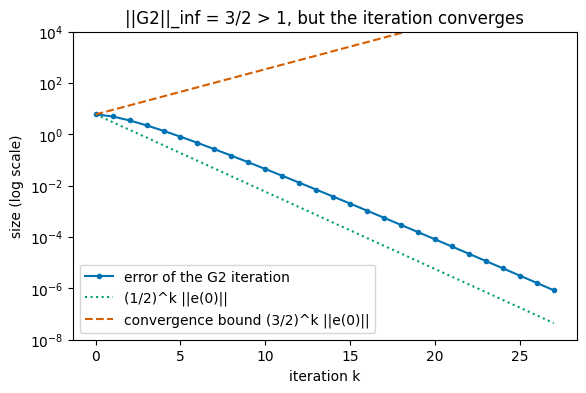

In [42]:
kk = np.arange(len(errors11))
fig, ax = plt.subplots(figsize=(6.5, 4))
ax.semilogy(kk, errors11, "o-", color=OI[0], markersize=3, label="error of the G2 iteration")
ax.semilogy(kk, errors11[0] * 0.5**kk, ":", color=OI[2], label="(1/2)^k ||e(0)||")
ax.semilogy(kk, errors11[0] * 1.5**kk, "--", color=OI[1], label="convergence bound (3/2)^k ||e(0)||")
ax.set_ylim(1e-8, 1e4)
ax.set_xlabel("iteration k")
ax.set_ylabel("size (log scale)")
ax.set_title("||G2||_inf = 3/2 > 1, but the iteration converges")
ax.legend()
plt.show()

**Interpret.**

(a) Why can the convergence bound not predict this?

*Sample answer.* With $\|G_2\|_\infty = 3/2 > 1$ the bound $(3/2)^k\|\mathbf{e}^{(0)}\|$ grows, so it says nothing about convergence. The bound is only a sufficient condition.

(b) `np.linalg.eigvals(G2)`: how does $\max|\lambda|$ relate to the observed rate?

*Sample answer.* Both eigenvalues are ½, and the error ratios approach ½ (slowly, because of the $k\,2^{1-k}$ term in $G_2^k$). The iteration converges to $\bar{\mathbf{x}} = (6, 2)$ because every $|\lambda| < 1$.

**Takeaway.** ‖G‖ < 1 guarantees convergence; the exact condition is that every |λ| < 1.

**Confidence check, Topic 11.** Mark one: Got it ☐ · Getting there ☐ · Need more practice ☐

## Topic 12 (If time). Conditioning vs. stability, with κ printed
*Mode: Run and interpret · AI use: Level 0 (AI Free) · About 8 min · optional · builds on PS2 Ex 7*

**Goal:** tell a sensitive problem from an unstable algorithm using κ and the residual.

**Connect.** In PS2 Ex 7 you sorted failures into conditioning (problem) and stability (algorithm).

**Run.** The toolkit function `solve_nopivot` does 2×2 elimination **without** row swaps. Case 1 is the tiny-pivot system; Case 2 is $H_{10}$ with `np.linalg.solve`.

In [43]:
def solve_nopivot(A, b):
    # Solve a 2x2 system by Gaussian elimination WITHOUT row swaps (to show instability).
    m = A[1, 0] / A[0, 0]                   # multiplier: divides by the (possibly tiny) pivot
    u22 = A[1, 1] - m * A[0, 1]
    x2 = (b[1] - m * b[0]) / u22
    x1 = (b[0] - A[0, 1] * x2) / A[0, 0]
    return np.array([x1, x2])


print("Case 1: A = [[1e-20, 1], [1, 1]], b = (1, 2)")
A12 = np.array([[1e-20, 1.0], [1.0, 1.0]])
b12 = np.array([1.0, 2.0])
x_nopivot = solve_nopivot(A12, b12)
x_pivot = np.linalg.solve(A12, b12)
show("kappa_2, kappa_inf", f"{np.linalg.cond(A12):.4f}, {np.linalg.cond(A12, np.inf):.4f}")
show("no pivoting: x", x_nopivot)
show("  residual ||b - A x||_inf", f"{np.linalg.norm(b12 - A12 @ x_nopivot, np.inf):.1e}")
show("np.linalg.solve (pivoting): x", x_pivot)
show("  residual ||b - A x||_inf", f"{np.linalg.norm(b12 - A12 @ x_pivot, np.inf):.1e}")

print("\nCase 2: H_10 x = H_10 (1, ..., 1) with np.linalg.solve")
H10 = hilbert(10)
x10 = np.ones(10)
b10 = H10 @ x10
xhat10 = np.linalg.solve(H10, b10)
show("kappa_2 (exact)", f"{hilbert_cond_exact(10):.2e}")
show("error ||x - xhat||_inf", f"{np.linalg.norm(x10 - xhat10, np.inf):.1e}")
show("residual ||b - H xhat||_inf", f"{np.linalg.norm(b10 - H10 @ xhat10, np.inf):.1e}")

Case 1: A = [[1e-20, 1], [1, 1]], b = (1, 2)
kappa_2, kappa_inf               2.6180, 4.0000
no pivoting: x                   [0. 1.]
  residual ||b - A x||_inf       1.0e+00
np.linalg.solve (pivoting): x    [1. 1.]
  residual ||b - A x||_inf       0.0e+00

Case 2: H_10 x = H_10 (1, ..., 1) with np.linalg.solve
kappa_2 (exact)                  1.60e+13
error ||x - xhat||_inf           7.4e-04
residual ||b - H xhat||_inf      4.4e-16


**Interpret.** Fill in the table (small or large), then answer in one sentence each.

| Case | κ | residual | error |
|---|---|---|---|
| 1, no pivoting | *Sample answer.* small (κ₂ ≈ 2.6, κ∞ = 4) | *Sample answer.* large (1) | *Sample answer.* large ((0, 1) instead of (1, 1)) |
| 2, $H_{10}$ | *Sample answer.* large (≈ 1.6 × 10¹³) | *Sample answer.* small (≈ 10⁻¹⁶) | *Sample answer.* large (many digits lost) |

Which failure would a better algorithm fix?

*Sample answer.* Case 1: yes, it is a stability failure; partial pivoting (`np.linalg.solve`) returns (1, 1). Case 2: no, it is a conditioning failure; the residual is already at rounding level, and only more precision or a better-posed problem would help.

**Takeaway.** Small residual and large error points to conditioning. Large residual with small κ points to an unstable algorithm.
$$\text{error} \lesssim \kappa \times \text{relative residual}.$$

**Confidence check, Topic 12.** Mark one: Got it ☐ · Getting there ☐ · Need more practice ☐

---
## Project toolkit
The cell below prints the source of every toolkit function defined in this notebook, ready to copy into later labs and the guided project. In the student version these are your own implementations. Functions from topics you skipped are listed as not defined.

In [44]:
toolkit = ["pnorm", "iterate", "grid_norms", "hilbert_cond_exact", "cholesky", "solve_cholesky", "solve_nopivot"]
for name in toolkit:
    if name in globals():
        print(inspect.getsource(globals()[name]))
    else:
        print(f"# {name}: not defined (its topic was skipped)\n")

def pnorm(x, p):
    # p-norm of the vector x, for p >= 1 or p = np.inf
    x = np.asarray(x, dtype=float)
    if p != np.inf:
        return np.sum(np.abs(x)**p)**(1/p)  # blank 1: (|x_1|^p + ... + |x_n|^p)^(1/p)
    return np.max(np.abs(x))  # blank 2: the largest entry in absolute value

def iterate(G, c, x0, tol, maxit):
    # Run x^(k+1) = G x^(k) + c until ||x^(k+1) - x^(k)||_inf <= tol (or maxit steps).
    # Returns the array of iterates [x^(0), x^(1), ..., x^(K)]; x0 may be a vector or 0.
    x_k = np.zeros(len(c)) + x0
    history = [x_k.copy()]
    for k in range(maxit):
        x_new = G @ x_k + c
        history.append(x_new)
        if np.linalg.norm(x_new - x_k, np.inf) <= tol:
            break
        x_k = x_new
    return np.array(history)

def grid_norms(f, a, b, N):
    # Approximate ||f||_inf, ||f||_1, ||f||_2 on [a, b] from N + 1 equally spaced points
    x = np.linspace(a, b, N + 1)
    y = f(x)
    h = (b - a) / N
    norm_inf = np.max(np.abs(y))  # blank 3: th

## Summary

| Topic | Problem set | Takeaway | Core or If time |
|---|---|---|---|
| 1. Norms of a vector | PS1 Ex 1–2 | The inequalities hold for every vector; √n is reached only when all \|xᵢ\| are equal. | Core |
| 2. The p-norm | PS1 Ex 3 | ‖x‖ₚ decreases to ‖x‖∞ as p → ∞, because the largest entry dominates. | Core |
| 3. Estimating ‖M‖∞ | PS1 Ex 4 | Sampling gives a lower bound for ‖A‖; the row-sum formula gives the exact value. | Core |
| 4. ‖Mᵏ‖ vs ‖M‖ᵏ | PS1 Ex 5 | Submultiplicativity always holds, but the gap can grow very fast. | Core |
| 5. Stopping test | PS1 Ex 6 | A small step is not a small error: up to ρ/(1 − ρ) times the last step. | Core |
| 6. Function norms on a grid | PS1 Ex 7 | Function norms are vector norms of samples, in the limit of a fine grid. | If time |
| 7. κ and the error bound | PS2 Ex 1–2 | κ is the worst-case amplification of relative errors in b; in ℝ² it is nearly reached. | Core |
| 8. κ and the Week 7 table | PS2 Ex 3 | Digits lost ≈ log₁₀κ; once κ ≳ 1/ε_mach nothing can be trusted. | Core |
| 9. Circle to ellipse | PS2 Ex 4 | ‖A‖₂ = σ_max, κ₂ = σ_max/σ_min: longest semi-axis and flatness. | Core |
| 10. Cholesky | PS2 Ex 5 | Cholesky is LU for SPD matrices with half the work, and also a test for SPD. | Core |
| 11. ‖G‖ > 1, still converges | PS2 Ex 6 | ‖G‖ < 1 guarantees convergence; the exact condition is every \|λ\| < 1. | If time |
| 12. Conditioning vs stability | PS2 Ex 7 | Small residual + large error: conditioning. Large residual + small κ: unstable algorithm. | If time |

## Confidence check
Mark one per outcome.

| Outcome | Got it | Getting there | Need more practice |
|---|---|---|---|
| A1. Compute vector norms; verify the norm inequalities | ☐ | ☐ | ☐ |
| A2. Implement the p-norm; explain the name ∞-norm | ☐ | ☐ | ☐ |
| A3. Explain why a sampled matrix norm falls short | ☐ | ☐ | ☐ |
| A4. Compare ‖Mᵏ‖ with ‖M‖ᵏ | ☐ | ☐ | ☐ |
| A5. Interpret error, step and stopping test | ☐ | ☐ | ☐ |
| A6. Approximate function norms on a grid | ☐ | ☐ | ☐ |
| B1. Compute κ; check the error bound | ☐ | ☐ | ☐ |
| B2. Predict digits lost; explain an unreliable computed κ | ☐ | ☐ | ☐ |
| B3. Relate singular values to the image of the unit circle | ☐ | ☐ | ☐ |
| B4. Use Cholesky to solve and to test for SPD | ☐ | ☐ | ☐ |
| B5. Distinguish conditioning from stability | ☐ | ☐ | ☐ |